# Mini-Project 2: Solar Micro-Grid Dispatch Planner

This project plans daily energy dispatch for a rural health centre in Kasese. The 30-day demand file is synthetic and reproducible: a seeded random generator builds solar and battery profiles with a weekly pattern plus noise, then derives the two demands from those non-negative source profiles. Values and costs are illustrative, not operational measurements.

Run the notebook from the repository root. The reusable implementation is in `src/microgrid.py` and tests are in `tests/test_microgrid.py`.

## 1. Model, determinant, and conditioning

The daily equations are `3x + 2y = D1` and `4x + y = D2`. The determinant tells us whether the 2x2 coefficient matrix is invertible: a non-zero determinant gives a unique solution. The condition number estimates how strongly relative input errors can be amplified in the solution; a value near 1 is well-conditioned, while a very large value warns that small demand errors can cause large dispatch changes.

In [1]:
from pathlib import Path

import numpy as np

from src.microgrid import (
    HybridMicroGrid,
    MicroGrid,
    generate_demo_csv,
    load_demand_csv,
    read_interactive_demands,
)

grid = MicroGrid()
print(f"Coefficient matrix:\n{grid.coefficient_matrix}")
print(f"Determinant: {grid.determinant:.3f}")
print(f"Condition number: {grid.condition_number:.3f}")
print(f"Well-posed: {grid.is_well_posed}")
print("Example [solar, battery] for D1=100, D2=90:", grid.solve_day(100, 90))

Coefficient matrix:
[[3. 2.]
 [4. 1.]]
Determinant: -5.000
Condition number: 5.828
Well-posed: True
Example [solar, battery] for D1=100, D2=90: [16. 26.]


## 2. Input options and 30-day CSV

`read_interactive_demands()` re-prompts for empty, non-numeric, infinite, or negative input. For the repeatable analysis below, the notebook writes and loads a 30-day CSV. Its seven-day profiles repeat weekly, while seeded Gaussian noise varies each day.

In [2]:
csv_path = generate_demo_csv(Path("data") / "microgrid_demand.csv", days=30, seed=42)
demands = load_demand_csv(csv_path)
print(f"Loaded {len(demands)} days from {csv_path}")
print("First five rows [D1, D2] (kWh):\n", demands[:5])

# To use interactive input instead, uncomment:
# d1, d2 = read_interactive_demands()
# print("Interactive dispatch [solar, battery]:", grid.solve_day(d1, d2))

Loaded 30 days from data\microgrid_demand.csv
First five rows [D1, D2] (kWh):
 [[108.798 120.542]
 [102.67  117.435]
 [114.557 135.093]
 [118.931 142.992]
 [109.206 129.787]]


## 3. Loop and vectorized solving

The loop calls `scipy.linalg.solve` once per day. The vectorized version passes one 2x30 right-hand side to a single solve call. Both methods should return the same result; timings are machine-dependent, and for a small 2x2 system Python-call overhead can dominate the arithmetic.

In [3]:
loop_solutions = grid.solve_days_loop(demands)
vectorized_solutions = grid.solve_days_vectorized(demands)
np.testing.assert_allclose(loop_solutions, vectorized_solutions)
timings = grid.benchmark(demands, number=100)
print(f"Loop:       {timings['loop_seconds'] * 1e3:.3f} ms/run")
print(f"Vectorized: {timings['vectorized_seconds'] * 1e3:.3f} ms/run")
print("The vectorized call reduces repeated Python/SciPy-call overhead; with only 30 days, elapsed times may be close and fluctuate.")

Loop:       12.342 ms/run
Vectorized: 0.526 ms/run
The vectorized call reduces repeated Python/SciPy-call overhead; with only 30 days, elapsed times may be close and fluctuate.


## 4. Feasibility, dispatch statistics, and cost

An exact solution with negative solar or battery use is physically infeasible. The planner flags those days and replaces their exact solution with a non-negative least-squares (NNLS) dispatch, which minimizes the remaining mismatch to the two demand equations. Solar costs UGX 150/kWh and battery energy UGX 450/kWh. Variance and standard deviation use the population convention (`ddof=0`).

In [4]:
results = grid.dispatch_days(demands, method="vectorized")
stats = grid.statistics(results)
infeasible_days = np.flatnonzero(results.infeasible) + 1
print("Infeasible exact-solution days (1-based):", infeasible_days.tolist())
print("Solar statistics:", stats["solar"])
print("Battery statistics:", stats["battery"])
print("More volatile source:", grid.more_volatile_source(stats))
print(f"30-day energy cost: UGX {results.monthly_cost:,.2f}")
print("First five daily costs (UGX):", np.round(results.daily_cost[:5], 2))

# Exercise the infeasibility policy on an intentionally inconsistent day.
example = grid.dispatch_days([[10, 50]])
print("Example D1=10, D2=50 flagged:", bool(example.infeasible[0]))
print("NNLS [solar, battery] dispatch:", [example.solar[0], example.battery[0]])

Infeasible exact-solution days (1-based): []
Solar statistics: {'mean': 29.158593333333336, 'variance': 6.519571454622221, 'standard_deviation': 2.553345149920437}
Battery statistics: {'mean': 11.590926666666668, 'variance': 2.378111534622229, 'standard_deviation': 1.5421126854488387}
More volatile source: solar
30-day energy cost: UGX 287,691.18
First five daily costs (UGX): [10589.52  9219.75  9434.28  9218.91  8782.71]
Example D1=10, D2=50 flagged: True
NNLS [solar, battery] dispatch: [np.float64(9.2), np.float64(0.0)]


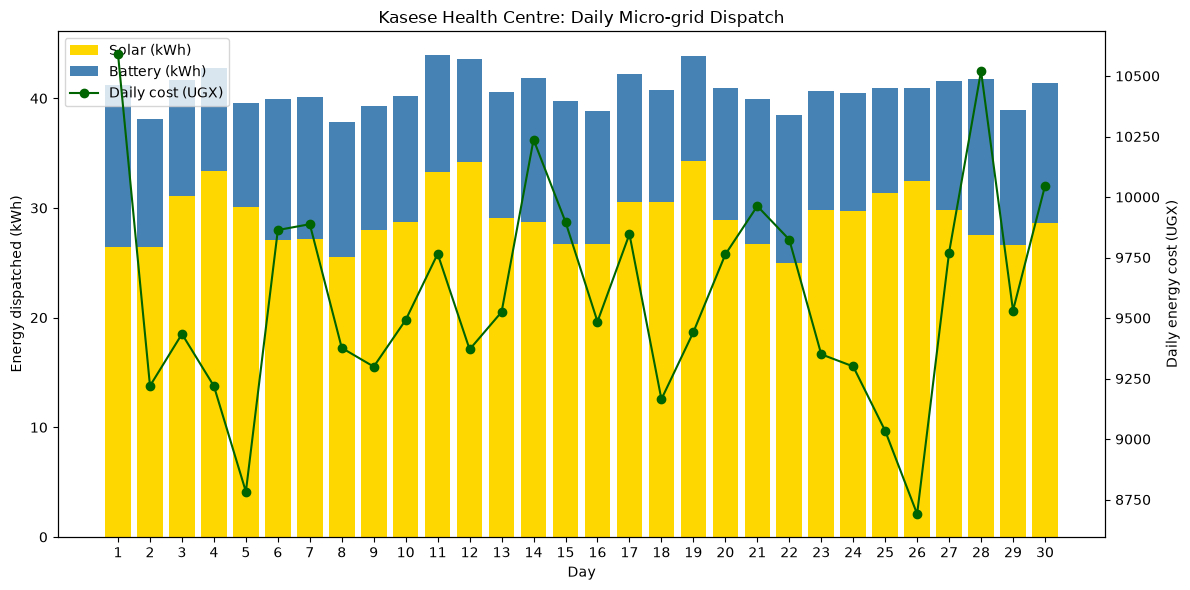

In [5]:
grid.plot_dispatch(results)

## 5. Sensitivity analysis

For one representative day, perturb each demand independently by a uniform random amount between -5% and +5%, repeated 1,000 times. The table reports mean and maximum absolute source changes and the mean change as a percentage of the baseline. The condition number provides an overall, norm-based indication of error amplification; the individual changes also depend on the specific coefficients and perturbation direction.

In [6]:
sensitivity = grid.sensitivity_analysis(*demands[0], draws=1000, relative_change=0.05, seed=7)
print(f"Matrix condition number: {grid.condition_number:.3f}")
for source, movement in sensitivity.items():
    print(source, movement)

Matrix condition number: 5.828
solar {'mean_absolute_change': 1.2835390210971673, 'maximum_absolute_change': 3.4057515124427873, 'mean_absolute_change_percent': np.float64(4.851378910456009)}
battery {'mean_absolute_change': 2.7063527592540333, 'maximum_absolute_change': 7.67684007254085, 'mean_absolute_change_percent': np.float64(18.3940458856947)}


## Extension: hybrid solar, battery, and diesel micro-grid

The third, illustrative constraint is total generation: `x + y + z = D3`. The resulting 3x3 matrix is invertible for the chosen coefficients. If the new equation is a linear combination of the first two, the determinant becomes zero and the system no longer has a unique solution; the class detects this and raises `numpy.linalg.LinAlgError` instead of returning a misleading dispatch.

In [7]:
hybrid = HybridMicroGrid()
hybrid_solution = hybrid.solve_day(100, 90, 40)
print("Hybrid coefficient matrix:\n", hybrid.coefficient_matrix)
print(f"Determinant: {hybrid.determinant:.3f}; condition number: {hybrid.condition_number:.3f}")
print("[solar, battery, diesel] kWh:", hybrid_solution)

dependent = HybridMicroGrid([[3, 2, 1], [4, 1, 2], [7, 3, 3]])
print(f"Dependent-equation determinant: {dependent.determinant:.3f}")
try:
    dependent.solve_day(100, 90, 40)
except np.linalg.LinAlgError as error:
    print("Expected failure:", error)

Hybrid coefficient matrix:
 [[3. 2. 1.]
 [4. 1. 2.]
 [1. 1. 1.]]
Determinant: -4.000; condition number: 10.059
[solar, battery, diesel] kWh: [17.5 25.  -2.5]
Dependent-equation determinant: 0.000
Expected failure: The demand system is singular or not numerically well-posed.
